In [ ]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

: 

## Data loading

In [ ]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
rhuh_dir = "Glioblastoma_RHUH-GBM_v2-29102025"
tcga_dir = "Glioblastoma_TCGA-GBM_v1-20170717"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1, 2, 3]
n_jobs = 16
nthreads = 2

DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

rhuh_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==2]["ID"].values]
rhuh_ids = [sub.replace('-0', '-', 1) for sub in rhuh_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{rhuh_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(rhuh_ids, desc="Loading RHUH maps")
)
maps_rhuh = np.vstack(results) # Nsubjects x nFeatures
maps_rhuh = np.where(maps_rhuh>=0, maps_rhuh, 0)

def delete_second_zero(text):
    splits = text.split('-')
    if len(splits) >= 3 and splits[2].startswith('0'):
        splits[2] = splits[2][1:]
    return '-'.join(splits)

tcga_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==3]["ID"].values]
tcga_ids = [delete_second_zero(sub) for sub in tcga_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{tcga_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(tcga_ids, desc="Loading TCGA maps")
)
maps_tcga = np.vstack(results)
maps_tcga = np.where(maps_tcga>=0, maps_tcga, 0)

maps_all = np.vstack((maps_ucsf, maps_upenn, maps_rhuh, maps_tcga))

maps_training = np.vstack((maps_ucsf, maps_upenn))
maps_testing = np.vstack((maps_rhuh, maps_tcga))

Log-rank test: chi-squared statistic of 0.3129840079623018 (p=0.9575683269152051)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


Loading UCSF maps:  22%|██▏       | 80/367 [00:01<00:06, 43.11it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:11<00:00, 44.18it/s]


In [3]:
maps_tcga = np.vstack(results)
maps_tcga = np.where(maps_tcga>=0, maps_tcga, 0)

maps_all = np.vstack((maps_ucsf, maps_upenn, maps_rhuh, maps_tcga))

maps_training = np.vstack((maps_ucsf, maps_upenn))
maps_testing = np.vstack((maps_rhuh, maps_tcga))

: 

## Datasets

In [ ]:
from dataset import Dataset
from transformer import Transformer, Projector
import scipy.integrate
scipy.integrate.trapz = np.trapezoid
from lifelines import CoxPHFitter
    
import matplotlib.pyplot as plt
from pipeline_encoder import EncodingPipeline
from results_saving import save_results

In [ ]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1
RHUH_SITE_IDX = 3
TCGA_SITE_IDX = 2

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()
data_rhuh = DATA[DATA['site'] == RHUH_SITE_IDX].copy()
data_tcga = DATA[DATA['site'] == TCGA_SITE_IDX].copy()

data_training = pd.concat([data_ucsf, data_upenn], ignore_index=True)
data_testing = pd.concat([data_rhuh, data_tcga], ignore_index=True)

dataset_training = Dataset("ucsf+upenn", "path/1", maps_training, data_training)
dataset_testing = Dataset("rhuh+tcga", "path/2", maps_testing, data_testing)

df_training = dataset_training.df
df_testing = dataset_testing.df
training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

duration_col = 'OS (corrected)'
event_col = 'status'

In [32]:
from data_transformer import DataTransformer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter


class Combiner:
    def __init__(self, method, feature_extraction_method, n_components):
            self.method = method
            self.feature_extraction_method = feature_extraction_method
            self.n_components = n_components

    def train_method(self, normalization):
        trainer = Transformer(self.method)
        comps_training = trainer.fit_transform(norm=normalization)
        comps_testing = trainer.transform(testing_maps)

        return comps_training, comps_testing
    
    def combine_with_clinical(self, df_training, df_testing, comps_training, comps_testing):
        df_base_train = df_training
        df_base_train = df_base_train.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
        X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base_train, comps_training, self.method, n_components=self.n_components)
        # self.encoding_pipeline = EncodingPipeline(X_train_with_features)
        # X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

        df_base_test = df_testing
        df_base_test = df_base_test.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
        X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base_test, comps_testing, self.method, n_components=self.n_components)
        # X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

        return X_train_with_features, X_test_with_features
    

    def encode(self, encoding_pipeline: EncodingPipeline, X_train_with_features, X_test_with_features):
        X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

        X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

        return X_train, X_test
    

    def __run(self, encoding_pipeline: EncodingPipeline):
        comps_training, comps_testing = self.train_method()
        X_train_with_features, X_test_with_features = self.combine_with_clinical(df_training, df_testing, comps_training, comps_testing)
        enc_pipeline = encoding_pipeline(X_train_with_features)
        X_train, X_test = self.encode(enc_pipeline, X_train_with_features, X_test_with_features)

        return X_train, X_test
    
    def compute_correlation(self, correlation_computer, X_train, duration_col):
        sorted_correlations = correlation_computer.compute_correlations(X_train, duration_col)
        return sorted_correlations
    


class CorrelationComputer:
    
    @staticmethod
    def compute_correlations(X_train, duration_col):
        prefix = "NMF_Comp_"
        raw_components = [col for col in X_train.columns if col.startswith(prefix)]
        correlations = X_train[raw_components].corrwith(X_train[duration_col])
        sorted_correlations = correlations.abs().sort_values(ascending=False)
        return sorted_correlations
    

from enum import Enum


class FeatureExtractionMethod(Enum):
    NMF = "NMF"
    PCA = "PCA"
    CosineKernelPCA = "cosine"

    @property
    def prefix(self) -> str:
        return f"{self.value}_Comp_"
    

class ComponentsPowerComputer:
    def __init__(self, method, feature_extraction_method: FeatureExtractionMethod, n_components, normalization):
        self.method = method
        self.feature_extraction_method = feature_extraction_method
        self.n_components = n_components
        self.normalization = normalization

    
    def compute_components_power(self):
        X_train = self.X_train if hasattr(self, 'X_train') else None
        X_test = self.X_test if hasattr(self, 'X_test') else None

        if X_train is None or X_test is None:
            raise ValueError("X_train and X_test must be computed before calculating component power.")

        
        RANDOM_GUESSING_C_INDEX = 0.5

        raw_components = [col for col in X_train.columns if col.startswith(self.feature_extraction_method.prefix)]
        component_scores = {}

        for comp in raw_components:
            df_subset = X_train[[comp, duration_col, event_col]]
            cph_uni = CoxPHFitter(penalizer=0)
            
            try:
                cph_uni.fit(df_subset, duration_col, event_col)
                power = cph_uni.concordance_index_ - RANDOM_GUESSING_C_INDEX
                component_scores[comp] = power
            except Exception as e:
                print(f"Skipped {comp} due to error: {e}")
                component_scores[comp] = 0.0


        components_sorted_by_power = sorted(component_scores, key=component_scores.get, reverse=True)
        sorted_component_scores = {comp: component_scores[comp] for comp in components_sorted_by_power}

        return components_sorted_by_power, sorted_component_scores



    def find(self):
        combiner = Combiner(self.method, self.feature_extraction_method,self.n_components)
        comps_training, comps_testing = combiner.train_method(normalization=self.normalization)
        X_train_with_features, X_test_with_features = combiner.combine_with_clinical(df_training, df_testing, comps_training, comps_testing)
        print("KOLUMNY PO DODANIU MAP:", X_train_with_features.columns.tolist()) # <--- TEN PRINT
        print(X_train_with_features.columns)
        print(X_train_with_features)
        encoding_pipeline = EncodingPipeline(X_train_with_features)
        X_train, X_test = combiner.encode(encoding_pipeline, X_train_with_features, X_test_with_features)
        print("KOLUMNY PO PIPELINE:", X_train.columns.tolist())
        self.X_train = X_train
        self.X_test = X_test

        # combiner = Combiner(method, n_components)
        # X_train, X_test = combiner.__run(EncodingPipeline)

        components_sorted_by_power, sorted_component_scores = self.compute_components_power()
        return components_sorted_by_power, sorted_component_scores


class ComponentsPowerComputerPlotter:

    @staticmethod
    def plot_top_components(components_sorted_by_power, component_scores, abs: bool =False, saving_path: str = None):
        power_series = pd.Series(component_scores).loc[components_sorted_by_power]
        top_10_power = power_series[:10]

        top_10_abs_keys = power_series.abs().sort_values(ascending=False).index[:10]
        top_10_abs_power = power_series.loc[top_10_abs_keys]

        plt.figure(figsize=(12, 6))
        # top_10_power.plot(kind='barh', color='skyblue', edgecolor='black')
        if abs:
            top_10_abs_power.iloc[::-1].plot(kind='barh', color='skyblue', edgecolor='black')
        else:
            top_10_power.plot(kind='barh', color='skyblue', edgecolor='black')
        plt.axvline(0, color='black', linestyle='-', linewidth=1)

        plt.title("Top 10 NMF Components by Absolute Predictive Power\n(C-Index - 0.5)", fontsize=14, fontweight='bold')
        plt.xlabel("Power (Distance from random guessing)", fontsize=12)
        plt.ylabel("Components", fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()
        plt.show()

        if saving_path is not None:
            plt.savefig(saving_path, format='svg', dpi=300)
            

In [ ]:
class ComponentsSelector:
    def __init__(self, clinical_columns, dataset_training, dataset_testing, duration_col, event_col, extraction_method: FeatureExtractionMethod):
        self.history_k = []
        self.history_train_ci = []
        self.history_test_ci = []

        self.clinical_columns = clinical_columns
        self.duration_col = duration_col
        self.event_col = event_col

        self.dataset_training = dataset_training
        self.dataset_testing = dataset_testing

        self.extraction_method = extraction_method

    def find_components(self, cph: CoxPHFitter, components_sorted_by_power: list, X_train : pd.DataFrame, X_test : pd.DataFrame, save_results_name: str | None = None, round_decimals: int = 5):
        # Iterate over possible components number
        for k in range(1, len(components_sorted_by_power) + 1):
            current_components = components_sorted_by_power[:k]
            
            selected_features = self.clinical_columns + current_components + [self.duration_col, self.event_col]
            
            X_train_subset = X_train[selected_features]
            X_test_subset = X_test[selected_features]

            try:
                cph.fit(X_train_subset, self.duration_col, self.event_col)
            except Exception as e:
                print(f"Fitting error for k={k} components: {e}")
                continue
                
            train_c_index = cph.concordance_index_
            c_index_test = cph.score(X_test_subset, "concordance_index")
            
            self.history_k.append(k)
            self.history_train_ci.append(train_c_index)
            self.history_test_ci.append(c_index_test)

            if save_results_name is not None:
                extraction_method = self.extraction_method.value
                penalizer = cph.penalizer if hasattr(cph, 'penalizer') else None

                results = {
                    "extraction_method": extraction_method,
                    "training_dataset": self.dataset_training.name,
                    "testing_dataset": self.dataset_testing.name,
                    "n_components": k,  
                    "penalizer": penalizer,
                    "ci_training": round(train_c_index, round_decimals),
                    "ci_testing": round(c_index_test, round_decimals),
                    "covariates": self.clinical_columns + current_components,
                    "duration_col": self.duration_col,
                    "event_col": self.event_col
                }
                save_results(results, save_results_name)


class ComponentsSelectorPlotter:
    def __init__(self, components_finder: ComponentsSelector):
        self.components_finder = components_finder

        self.history_k = components_finder.history_k
        self.history_train_ci = components_finder.history_train_ci
        self.history_test_ci = components_finder.history_test_ci

    def plot_c_index(self, title: str, savefig: bool, savefig_filename: str, testing_baseline: float | None = None):
        if self.history_k:
            plt.figure(figsize=(10, 6))
            plt.plot(self.history_k, self.history_train_ci, label='Training C-Index', color='blue', linewidth=2)
            plt.plot(self.history_k, self.history_test_ci, label='Testing C-Index', color='orange', linewidth=2)

            if testing_baseline is not None:
                plt.axhline(y=testing_baseline, color='gray', linestyle=':', linewidth=2,
                            label=f'Testing Baseline ({testing_baseline:.4f})')
            
            plt.title(title, fontsize=14)
            plt.xlabel("Number of added components (from strongest to weakest signal)", fontsize=12)
            plt.ylabel("Concordance Index", fontsize=12)
            
            best_k_idx = np.argmax(self.history_test_ci)
            plt.axvline(x=self.history_k[best_k_idx], color='red', linestyle='--', 
                        label=f'Best Test CI (k={self.history_k[best_k_idx]})')
            
            plt.legend()
            plt.grid(True, linestyle=':', alpha=0.7)
            
            if savefig:
                plt.savefig(savefig_filename, bbox_inches='tight')
            plt.show()

    
class ResultsHolder:
    def __init__(self, history_k, history_train_ci, history_test_ci):
        self.history_k = history_k
        self.history_train_ci = history_train_ci
        self.history_test_ci = history_test_ci


    @property
    def best_k_idx(self):
        if self.history_test_ci:
            best_idx = np.argmax(self.history_test_ci)
            return best_idx
        return None

In [ ]:
# from nmf import NMFProjections


# feature_extraction_method = FeatureExtractionMethod.NMF

# normalization = None
# n_components= 100

# method = NMFProjections(training_maps=training_maps, template=T1, binary_mask=T1_brain, n_components=n_components)

In [17]:
# from KernelPCA import TD_Kernel_PCA


# feature_extraction_method = FeatureExtractionMethod.CosineKernelPCA

# normalization = None
# n_components= 100

# method = TD_Kernel_PCA(training_maps=training_maps, template=T1, binary_mask=T1_brain, n_components=n_components, kernel="cosine")

In [ ]:
from TractDensityComponents import TD_PCA


feature_extraction_method = FeatureExtractionMethod.PCA

normalization = None
n_components= 100

method = TD_PCA(training_maps=training_maps, template=T1, binary_mask=T1_brain, n_components=n_components)

In [34]:
X_train

,sex,age,EOR,MGMT,status,OS (corrected)
0,1.0,0.645100,0.5,0.0,1.0,389.000000
1,0.0,0.617800,0.5,0.0,1.0,1303.000000
2,0.0,0.672400,0.5,0.0,1.0,185.000000
3,1.0,0.645100,0.5,1.0,0.0,133.000000
4,1.0,0.590500,0.5,1.0,1.0,313.000000
...,...,...,...,...,...,...
858,0.0,0.541087,1.0,0.0,1.0,2096.001141
859,1.0,0.807535,0.5,1.0,1.0,891.972370
860,1.0,0.647147,0.5,1.0,1.0,1372.780300
861,0.0,0.509828,0.5,1.0,1.0,737.953117


In [33]:
components_power_computer = ComponentsPowerComputer(method, feature_extraction_method, n_components, normalization)
components_sorted_by_power, sorted_component_scores = components_power_computer.find()
X_train, X_test = components_power_computer.X_train, components_power_computer.X_test

INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!
(863, 100)
100
(136, 100)
100
KOLUMNY PO DODANIU MAP: ['sex', 'age', 'status', 'EOR', 'MGMT', 'OS (corrected)', 'PCA_Comp_1', 'PCA_Comp_2', 'PCA_Comp_3', 'PCA_Comp_4', 'PCA_Comp_5', 'PCA_Comp_6', 'PCA_Comp_7', 'PCA_Comp_8', 'PCA_Comp_9', 'PCA_Comp_10', 'PCA_Comp_11', 'PCA_Comp_12', 'PCA_Comp_13', 'PCA_Comp_14', 'PCA_Comp_15', 'PCA_Comp_16', 'PCA_Comp_17', 'PCA_Comp_18', 'PCA_Comp_19', 'PCA_Comp_20', 'PCA_Comp_21', 'PCA_Comp_22', 'PCA_Comp_23', 'PCA_Comp_24', 'PCA_Comp_25', 'PCA_Comp_26', 'PCA_Comp_27', 'PCA_Comp_28', 'PCA_Comp_29', 'PCA_Comp_30', 'PCA_Comp_31', 'PCA_Comp_32', 'PCA_Comp_33', 'PCA_Comp_34', 'PCA_Comp_35', 'PCA_Comp_36', 'PCA_Comp_37', 'PCA_Comp_38', 'PCA_Comp_39', 'PCA_Comp_40', 'PCA_Comp_41', 'PCA_Comp_42', 'PCA_Comp_43', 'PCA_Comp_44', 'PCA_Comp

/home/joan/.conda/envs/neuro_2/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['PCA_Comp_1' 'PCA_Comp_2' 'PCA_Comp_3' 'PCA_Comp_4' 'PCA_Comp_5'
 'PCA_Comp_6' 'PCA_Comp_7' 'PCA_Comp_8' 'PCA_Comp_9' 'PCA_Comp_10'
 'PCA_Comp_11' 'PCA_Comp_12' 'PCA_Comp_13' 'PCA_Comp_14' 'PCA_Comp_15'
 'PCA_Comp_16' 'PCA_Comp_17' 'PCA_Comp_18' 'PCA_Comp_19' 'PCA_Comp_20'
 'PCA_Comp_21' 'PCA_Comp_22' 'PCA_Comp_23' 'PCA_Comp_24' 'PCA_Comp_25'
 'PCA_Comp_26' 'PCA_Comp_27' 'PCA_Comp_28' 'PCA_Comp_29' 'PCA_Comp_30'
 'PCA_Comp_31' 'PCA_Comp_32' 'PCA_Comp_33' 'PCA_Comp_34' 'PCA_Comp_35'
 'PCA_Comp_36' 'PCA_Comp_37' 'PCA_Comp_38' 'PCA_Comp_39' 'PCA_Comp_40'
 'PCA_Comp_41' 'PCA_Comp_42' 'PCA_Comp_43' 'PCA_Comp_44' 'PCA_Comp_45'
 'PCA_Comp_46' 'PCA_Comp_47' 'PCA_Comp_48' 'PCA_Comp_49' 'PCA_Comp_50'
 'PCA_Comp_51' 'PCA_Comp_52' 'PCA_Comp_53' 'PCA_Comp_54' 'PCA_Comp_55'
 'PCA_Comp_56' 'PCA_Comp_57' 'PCA_Comp_58' 'PCA_Comp_59' 'PCA_Comp_60'
 'PCA_Co

In [15]:
components_power_computer = ComponentsPowerComputer(method, feature_extraction_method, n_components, normalization)
components_sorted_by_power, sorted_component_scores = components_power_computer.find()
X_train, X_test = components_power_computer.X_train, components_power_computer.X_test

raw_components = [col for col in X_train.columns if col.startswith(feature_extraction_method.prefix)]
clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]
components_finder = ComponentsSelector(clinical_columns, dataset_training, dataset_testing, duration_col, event_col, feature_extraction_method)
cph = CoxPHFitter(penalizer=0.1)
components_finder.find_components(cph, components_sorted_by_power, X_train, X_test, save_results_name="nmf_incremental_results.csv")

components_finder_plotter = ComponentsSelectorPlotter(components_finder)
components_finder_plotter.plot_c_index(title="Impact of Number of NMF Components (Sorted by Univariate Cox)\non Model Performance", savefig=True, savefig_filename="results-incremental/nmf_incremental_curve.png", testing_baseline=0.658100)

results_holder = ResultsHolder(components_finder.history_k, components_finder.history_train_ci, components_finder.history_test_ci)
history_k = results_holder.history_k
best_k_idx = results_holder.best_k_idx

if best_k_idx is None:
    raise ValueError("No valid Cox model was fitted. Check the fitting errors printed by ComponentsSelector.find_components().")

best_k = history_k[best_k_idx]
current_features = components_sorted_by_power[:best_k]
# clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]

selected_features = clinical_columns + current_features + [duration_col, event_col]
X_train_subset = X_train[selected_features]

cph = CoxPHFitter(penalizer=0.501, l1_ratio=0.501)
cph.fit(X_train_subset, duration_col, event_col)

from lifelines import KaplanMeierFitter
import lifelines

INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!
(863, 100)
100
(136, 100)
100


/home/joan/.conda/envs/neuro_2/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['PCA_Comp_1' 'PCA_Comp_2' 'PCA_Comp_3' 'PCA_Comp_4' 'PCA_Comp_5'
 'PCA_Comp_6' 'PCA_Comp_7' 'PCA_Comp_8' 'PCA_Comp_9' 'PCA_Comp_10'
 'PCA_Comp_11' 'PCA_Comp_12' 'PCA_Comp_13' 'PCA_Comp_14' 'PCA_Comp_15'
 'PCA_Comp_16' 'PCA_Comp_17' 'PCA_Comp_18' 'PCA_Comp_19' 'PCA_Comp_20'
 'PCA_Comp_21' 'PCA_Comp_22' 'PCA_Comp_23' 'PCA_Comp_24' 'PCA_Comp_25'
 'PCA_Comp_26' 'PCA_Comp_27' 'PCA_Comp_28' 'PCA_Comp_29' 'PCA_Comp_30'
 'PCA_Comp_31' 'PCA_Comp_32' 'PCA_Comp_33' 'PCA_Comp_34' 'PCA_Comp_35'
 'PCA_Comp_36' 'PCA_Comp_37' 'PCA_Comp_38' 'PCA_Comp_39' 'PCA_Comp_40'
 'PCA_Comp_41' 'PCA_Comp_42' 'PCA_Comp_43' 'PCA_Comp_44' 'PCA_Comp_45'
 'PCA_Comp_46' 'PCA_Comp_47' 'PCA_Comp_48' 'PCA_Comp_49' 'PCA_Comp_50'
 'PCA_Comp_51' 'PCA_Comp_52' 'PCA_Comp_53' 'PCA_Comp_54' 'PCA_Comp_55'
 'PCA_Comp_56' 'PCA_Comp_57' 'PCA_Comp_58' 'PCA_Comp_59' 'PCA_Comp_60'
 'PCA_Co

ValueError: No valid Cox model was fitted. Check the fitting errors printed by ComponentsSelector.find_components().

Train low/high sizes: 216 / 216
Test low/high sizes: 34 / 34


<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic      p  -log2(p)
          11.56 <0.005     10.53

654.9166504110113
             High Risk_lower_0.95  High Risk_upper_0.95
0.000000                 1.000000              1.000000
15.000000                1.000000              1.000000
16.071574                0.967446              0.999344
17.410872                0.963321              0.997665
28.000000                0.957367              0.995478
...                           ...                   ...
3369.673400              0.011604              0.074800
3608.068418              0.007138              0.063899
3952.267966              0.003400              0.052523
5012.991866              0.003400              0.052523
8216.592332              0.003400              0.052523

[200 rows x 2 columns]


<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           0.07 0.79      0.34

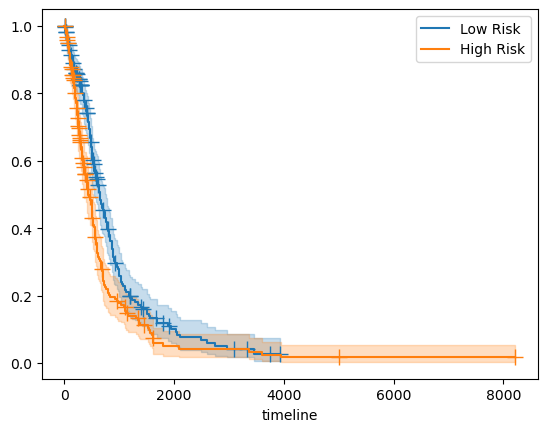

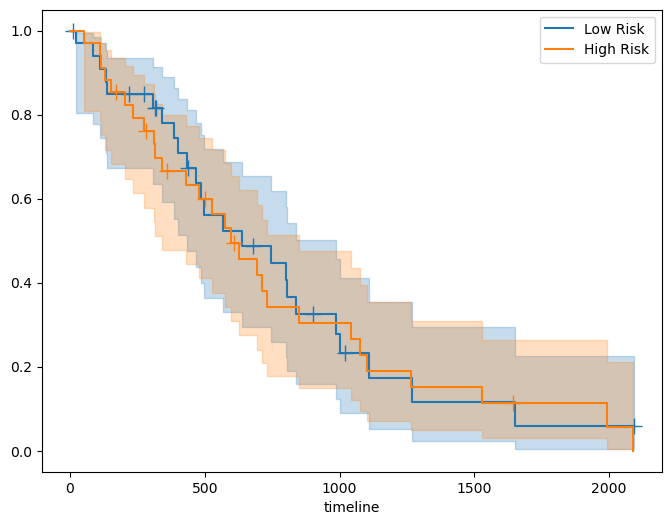

In [10]:
component_betas = cph.params_.loc[current_features].to_numpy()
PCs = X_train[current_features].to_numpy()
PCS_test = X_test[current_features].to_numpy()

risk_scores = np.dot(PCs, component_betas)
risk_scores_test = np.dot(PCS_test, component_betas)

p = 25

finite_train = np.isfinite(risk_scores)
finite_test = np.isfinite(risk_scores_test)

if not finite_train.any():
    raise ValueError("risk_scores for the training set contain no finite values")
if not finite_test.any():
    raise ValueError("risk_scores_test for the testing set contain no finite values")

train_order = np.argsort(risk_scores[finite_train])
test_order = np.argsort(risk_scores_test[finite_test])

train_positions = np.flatnonzero(finite_train)
test_positions = np.flatnonzero(finite_test)

n_train_group = max(1, int(np.ceil(len(train_order) * p / 100)))
n_test_group = max(1, int(np.ceil(len(test_order) * p / 100)))

low_risk = np.zeros(len(risk_scores), dtype=bool)
high_risk = np.zeros(len(risk_scores), dtype=bool)
low_risk[train_positions[train_order[:n_train_group]]] = True
high_risk[train_positions[train_order[-n_train_group:]]] = True

low_risk_test = np.zeros(len(risk_scores_test), dtype=bool)
high_risk_test = np.zeros(len(risk_scores_test), dtype=bool)
low_risk_test[test_positions[test_order[:n_test_group]]] = True
high_risk_test[test_positions[test_order[-n_test_group:]]] = True

print(f"Train low/high sizes: {low_risk.sum()} / {high_risk.sum()}")
print(f"Test low/high sizes: {low_risk_test.sum()} / {high_risk_test.sum()}")

kmf_low = KaplanMeierFitter()
kmf_high = KaplanMeierFitter()
kmf_low.fit(df_training.loc[low_risk, duration_col], event_observed=df_training.loc[low_risk, event_col], label='Low Risk')
kmf_high.fit(df_training.loc[high_risk, duration_col], event_observed=df_training.loc[high_risk, event_col], label='High Risk')
kmf_low.plot_survival_function(show_censors=True)#, at_risk_counts=True)
kmf_high.plot_survival_function(show_censors=True)#, at_risk_counts=True)

lifelines.statistics.logrank_test(
    df_training.loc[low_risk, duration_col],
    df_training.loc[high_risk, duration_col],
    event_observed_A=df_training.loc[low_risk, event_col],
    event_observed_B=df_training.loc[high_risk, event_col]
).print_summary()


daysXmonth = 365 / 12
print(kmf_low.median_survival_time_) #/ daysXmonth, kmf_high.median_survival_time_ / daysXmonth


print(kmf_high.confidence_interval_)

fig, ax = plt.subplots(figsize=(8, 6))

kmf_high_test = KaplanMeierFitter()
kmf_low_test = KaplanMeierFitter()
kmf_low_test.fit(df_testing.loc[low_risk_test, duration_col], event_observed=df_testing.loc[low_risk_test, event_col], label='Low Risk')
kmf_high_test.fit(df_testing.loc[high_risk_test, duration_col], event_observed=df_testing.loc[high_risk_test, event_col], label='High Risk')
kmf_low_test.plot_survival_function(show_censors=True, )
kmf_high_test.plot_survival_function(show_censors=True) 

lifelines.statistics.logrank_test(
    df_testing.loc[low_risk_test, duration_col],
    df_testing.loc[high_risk_test, duration_col],
    event_observed_A=df_testing.loc[low_risk_test, event_col],
    event_observed_B=df_testing.loc[high_risk_test, event_col]
).print_summary()